# Exploratory Data Analysis: Root Cross-Section Segmentation

Exploratory dataset analysis focusing on biological specimen groupings, cross-section subtypes, and leakage auditing for nnU-Net v2 conversion.

## 1. Environment Setup & Configuration

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from hydra import compose, initialize
import rootutils
from PIL import Image

# Setup project root and pythonpath
rootutils.setup_root(Path.cwd(), indicator="pyproject.toml", pythonpath=True)

import src.utils.resolvers

# Load Hydra configuration
with initialize(version_base="1.3", config_path="../cfg"):
    cfg = compose(config_name="config")

# Import domain utilities
from src.utils.coco import (
    load_coco, extract_group, get_mapped_classes, 
    normalize_name, rasterize_annotations, resolve_draw_order
)
from src.utils.convert import make_grouped_partition

## 2. Dataset Ingestion & Specimen Metadata Extraction

Parse Roboflow COCO annotations across all configured splits and extract biological specimen identifiers (`group`) and section subtypes (`subgroup`).

In [2]:
# Read split configurations from Hydra
dataset_dir = Path(cfg.paths.dataset)
split_cfg = cfg.export.split

group_pattern = split_cfg.group_pattern
subgroup_pattern = split_cfg.get("subgroup_pattern")

records = []
for split_name in cfg.export.roboflow_splits:
    split_dir = dataset_dir / split_name
    if not split_dir.is_dir():
        continue

    coco = load_coco(split_dir)
    for img in coco["images"]:
        file_name = img["file_name"]

        # Extract specimen identifier and section subtype
        group = extract_group(file_name, group_pattern)
        subgroup = extract_group(file_name, subgroup_pattern) if subgroup_pattern else None

        records.append({
            "key": f"{split_name}/{file_name}",
            "roboflow_split": split_name,
            "file_name": file_name,
            "group": group,
            "subgroup": subgroup,
            "width": img["width"],
            "height": img["height"],
        })

df_cases = pd.DataFrame(records)
unique_groups = sorted(df_cases["group"].unique())
unique_subgroups = sorted(df_cases["subgroup"].dropna().unique())

print(f"Total images: {len(df_cases)}")
print(f"Unique specimen groups ({len(unique_groups)}): {unique_groups}")
if subgroup_pattern:
    print(f"Unique subgroups ({len(unique_subgroups)}): {unique_subgroups}")

Total images: 150
Unique specimen groups (20): ['1501', '1502', '1503', '1504', '1505', '1601', '1602', '1603', '1604', '1605', '1701', '1702', '1703', '1704', '1705', '1801', '1802', '1803', '1804', '1805']
Unique subgroups (2): ['1', '2']


## 3. Specimen Distribution & Subgroup Breakdown

Inspect the number of cross-section images per biological specimen and examine how subtypes are distributed across groups.

In [3]:
# Summary of cross-section images per biological specimen
print("--- Images per Specimen Summary ---")
print(df_cases.groupby("group").size().describe())

# Distribution of section subtypes across biological specimens
if subgroup_pattern:
    print("\n--- Subgroup Distribution by Specimen ---")
    subgroup_dist = df_cases.groupby(["group", "subgroup"]).size().unstack(fill_value=0)
    display(subgroup_dist)

--- Images per Specimen Summary ---
count    20.000000
mean      7.500000
std       1.791794
min       4.000000
25%       7.750000
50%       8.000000
75%       8.000000
max      12.000000
dtype: float64

--- Subgroup Distribution by Specimen ---


subgroup,1,2
group,,
1501,8,4
1502,0,4
1503,0,4
1504,4,4
1505,4,4
1601,4,4
1602,4,4
1603,4,4
1604,4,4


## 4. Roboflow Split Leakage Audit

Check whether Roboflow's default assignment split slices of the same specimen across `train`, `valid`, and `test` subsets, causing data leakage.

In [4]:
# Audit specimen overlap across Roboflow subsets
leakage_by_group = df_cases.groupby("group")["roboflow_split"].nunique()
leaked_groups = leakage_by_group[leakage_by_group > 1]

if len(leaked_groups) > 0:
    print(f"[WARNING] Detected {len(leaked_groups)} specimen(s) split across Roboflow subsets (data leakage):")
    leaked_df = (
        df_cases[df_cases["group"].isin(leaked_groups.index)]
        .groupby(["group", "roboflow_split"])
        .size()
        .unstack(fill_value=0)
    )
    display(leaked_df)
else:
    print("[OK] No specimen overlap detected across Roboflow splits.")

# Subgroup balance across original Roboflow splits
if subgroup_pattern:
    print("\n--- Subgroup Distribution Across Roboflow Splits ---")
    display(df_cases.groupby(["roboflow_split", "subgroup"]).size().unstack(fill_value=0))

[WARNING] Detected 20 specimen(s) split across Roboflow subsets (data leakage):


roboflow_split,test,train,valid
group,,,
1501,2,8,2
1502,0,3,1
1503,0,3,1
1504,1,7,0
1505,0,6,2
1601,0,5,3
1602,1,4,3
1603,1,5,2
1604,1,7,0



--- Subgroup Distribution Across Roboflow Splits ---


subgroup,1,2
roboflow_split,,
test,9,6
train,47,58
valid,14,16


## 5. nnU-Net Grouped Partitioning Simulation

Simulate specimen-grouped partitioning to produce a held-out test set and balanced 5-fold cross-validation folds without data leakage.

In [5]:
# Prepare key-to-group mappings for partition search
group_of = dict(zip(df_cases["key"], df_cases["group"]))
subgroup_of = dict(zip(df_cases["key"], df_cases["subgroup"])) if subgroup_pattern else None

# Search for optimal test set and cross-validation folds
test_keys, fold_of = make_grouped_partition(
    group_of=group_of,
    subgroup_of=subgroup_of,
    test_frac=float(split_cfg.test_fraction),
    n_folds=int(split_cfg.n_folds),
    seed=int(split_cfg.seed),
)

# Assign partition assignments back to DataFrame
df_cases["nnunet_partition"] = df_cases["key"].apply(
    lambda k: "test" if k in test_keys else f"fold_{fold_of[k]}"
)

# Aggregate images and group counts per partition
partition_summary = df_cases.groupby(["nnunet_partition", "subgroup"]).size().unstack(fill_value=0)
partition_summary["total_images"] = partition_summary.sum(axis=1)
partition_summary["unique_groups"] = df_cases.groupby("nnunet_partition")["group"].nunique()

print("--- nnU-Net Grouped Partition Summary ---")
display(partition_summary)

--- nnU-Net Grouped Partition Summary ---


subgroup,1,2,total_images,unique_groups
nnunet_partition,,,,
fold_0,12,16,28,4
fold_1,12,12,24,3
fold_2,12,12,24,3
fold_3,12,12,24,3
fold_4,11,16,27,4
test,11,12,23,3


## 6. Partition Verification & Zero-Leakage Guarantee

Assert that each biological specimen is strictly isolated in exactly one partition (either the test set or a single training fold).

In [6]:
# Assert zero specimen leakage across nnU-Net partitions
partition_counts_per_group = df_cases.groupby("group")["nnunet_partition"].nunique()
multi_partition_groups = partition_counts_per_group[partition_counts_per_group > 1]

assert len(multi_partition_groups) == 0, (
    f"Leakage detected! Specimen groups assigned to multiple partitions: {list(multi_partition_groups.index)}"
)

print("[PASSED] Verification successful: every specimen is strictly isolated in a single partition.")

[PASSED] Verification successful: every specimen is strictly isolated in a single partition.


## 7. Image size analysis

Width/height distribution of the original images (all splits). nnU-Net picks its patch size from the median image size, so this shows how much the patch covers and how heterogeneous the resolutions are.

Total images: 150 | Max width: 2146 px | Max height: 2547 px


roboflow_split         test    train    valid
width        count    15.00   105.00    30.00
             mean   1133.27  1241.32  1249.53
             std     398.55   414.92   407.39
             min     740.00   542.00   594.00
             25%     824.50   887.00   960.00
             50%     995.00  1198.00  1075.00
             75%    1256.00  1495.00  1595.50
             max    2017.00  2146.00  2032.00
height       count    15.00   105.00    30.00
             mean   1142.40  1260.12  1296.67
             std     338.35   362.48   392.35
             min     740.00   590.00   749.00
             25%     912.00   953.00  1033.75
             50%    1034.00  1248.00  1243.50
             75%    1319.50  1516.00  1574.00
             max    1872.00  2166.00  2547.00
aspect_ratio count    15.00   105.00    30.00
             mean      0.99     0.98     0.96
             std       0.12     0.12     0.11
             min       0.73     0.73     0.77
             25%       0.94     0.91     0.89
             50%       0.97     0.97     0.95
             75%       1.05     1.04     1.04
             max       1.24     1.50     1.24

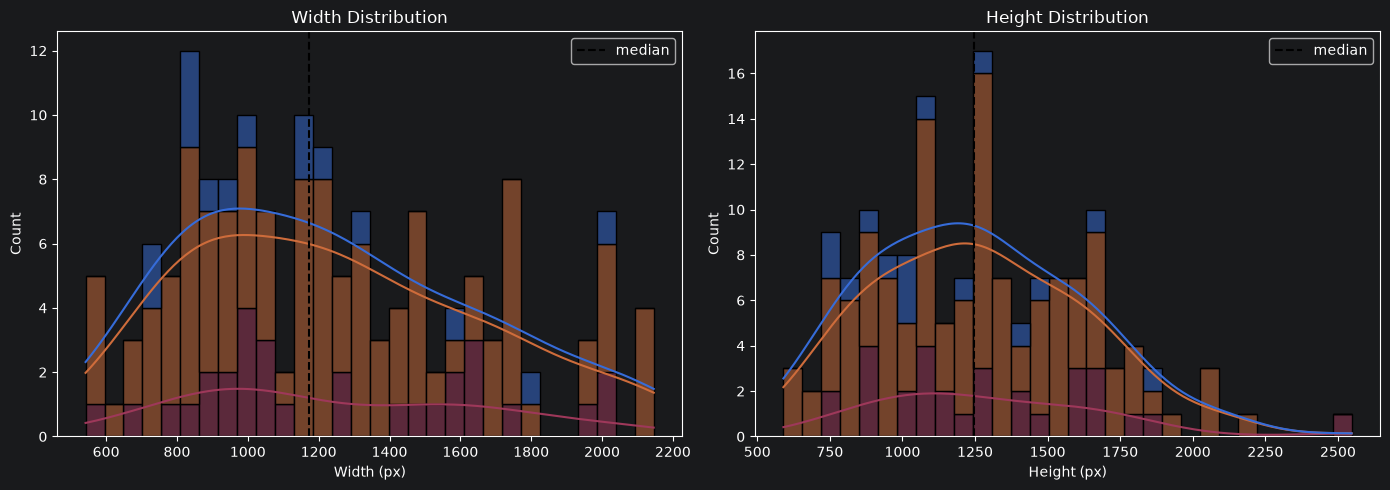

In [7]:
df_cases["aspect_ratio"] = df_cases["width"] / df_cases["height"]

print(f"Total images: {len(df_cases)} | Max width: {df_cases['width'].max()} px | Max height: {df_cases['height'].max()} px")
display(df_cases.groupby("roboflow_split")[["width", "height", "aspect_ratio"]].describe().round(2).T)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Width Distribution
sns.histplot(data=df_cases, x="width", hue="roboflow_split", kde=True, bins=30, multiple="stack", ax=axes[0])
axes[0].axvline(df_cases["width"].median(), color="black", linestyle="--", label="median")
axes[0].set_title("Width Distribution")
axes[0].set_xlabel("Width (px)")
axes[0].legend()

# Height Distribution
sns.histplot(data=df_cases, x="height", hue="roboflow_split", kde=True, bins=30, multiple="stack", ax=axes[1])
axes[1].axvline(df_cases["height"].median(), color="black", linestyle="--", label="median")
axes[1].set_title("Height Distribution")
axes[1].set_xlabel("Height (px)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Annotations per class and split

Number of COCO polygons per class. Classes like `root` and `stele` should appear once per image; others like `xylem` count individual vessels.

roboflow_split,test,train,valid,total
class,,,,
root,15,105,30,150
stele,15,105,30,150
xylem,892,5641,1736,8269


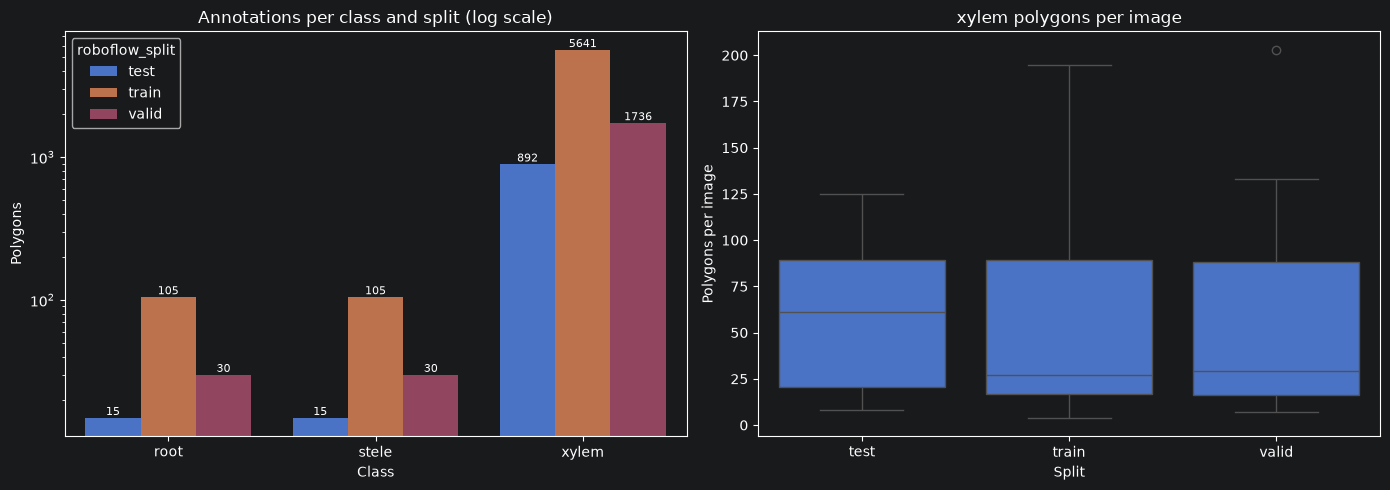

In [8]:
# Read valid classes from the first available split
first_split = cfg.export.roboflow_splits[0]
coco_first = load_coco(dataset_dir / first_split)
classes = get_mapped_classes(coco_first)

# Collect data: one row per (split, image, class) with polygon count
annotation_rows = []
for split_name in cfg.export.roboflow_splits:
    split_dir = dataset_dir / split_name
    if not split_dir.is_dir():
        continue

    coco = load_coco(split_dir)

    # Map category_id to normalized name
    cat_to_name = {}
    for c in coco["categories"]:
        norm_name = normalize_name(c["name"])
        if norm_name in classes:
            cat_to_name[c["id"]] = norm_name

    # Initialize counts to 0
    counts = {(img["id"], name): 0 for img in coco["images"] for name in classes}

    for ann in coco["annotations"]:
        name = cat_to_name.get(ann["category_id"])
        if name:
            counts[(ann["image_id"], name)] += 1

    annotation_rows += [
        {"roboflow_split": split_name, "image_id": img_id, "class": name, "annotations": n}
        for (img_id, name), n in counts.items()
    ]

annotations_df = pd.DataFrame(annotation_rows)

# Totals per split and class
annotation_totals = annotations_df.pivot_table(
    index="class", columns="roboflow_split", values="annotations", aggfunc="sum"
)[list(cfg.export.roboflow_splits)].reindex(list(classes.keys()))
annotation_totals["total"] = annotation_totals.sum(axis=1)
display(annotation_totals)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=annotations_df, x="class", y="annotations", hue="roboflow_split",
    estimator="sum", errorbar=None, order=list(classes.keys()), hue_order=list(cfg.export.roboflow_splits), ax=axes[0],
)
axes[0].set_yscale("log")
axes[0].set_title("Annotations per class and split (log scale)")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Polygons")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%d", fontsize=8)

xylem_name = list(classes.keys())[-1]
sns.boxplot(
    data=annotations_df[annotations_df["class"] == xylem_name],
    x="roboflow_split", y="annotations", order=list(cfg.export.roboflow_splits), ax=axes[1],
)
axes[1].set_title(f"{xylem_name} polygons per image")
axes[1].set_xlabel("Split")
axes[1].set_ylabel("Polygons per image")

plt.tight_layout()
plt.show()

## 9. Mask pixel distribution

Pixels per class in the masks rasterized from COCO (exactly what nnU-Net receives). Classes are exclusive: `root` only counts root pixels outside the stele, and `stele` only counts stele pixels outside the xylem vessels. This shows the class imbalance the loss has to deal with.

roboflow_split,test (%),train (%),valid (%),total (%)
class,,,,
background,45.24,43.53,42.19,43.40
root,34.68,37.13,36.58,36.81
stele,14.24,14.11,15.95,14.50
xylem,5.84,5.23,5.28,5.29


Imbalance (background pixels / class pixels):
  root: 1.2x
  stele: 3.0x
  xylem: 8.2x


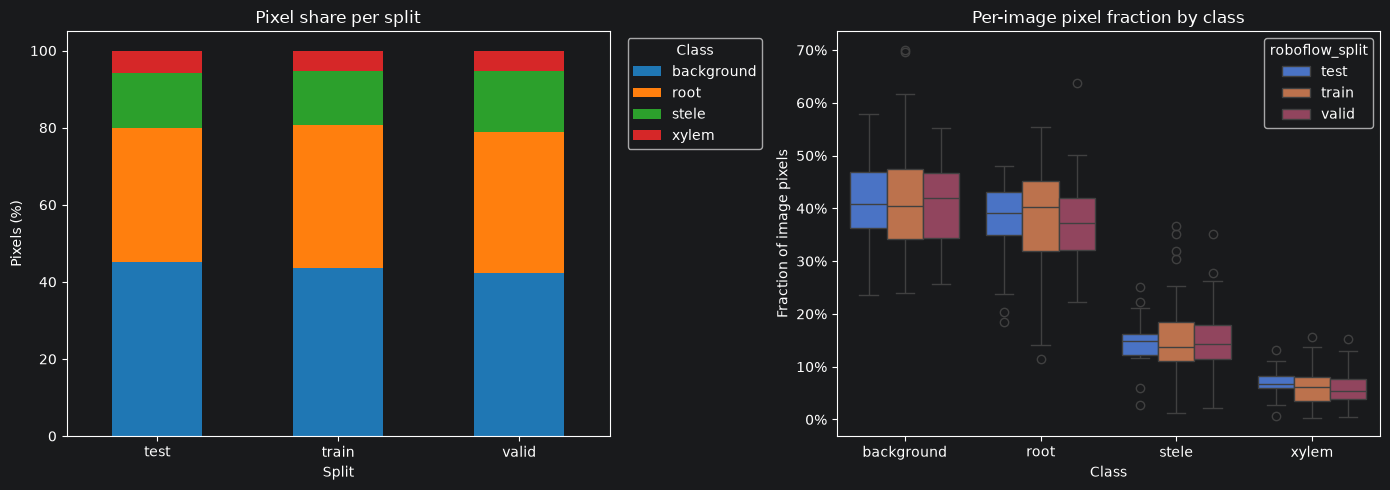

In [9]:
idx_to_class = {0: "background", **{value: name for name, value in classes.items()}}

# Determine draw order
draw_order_cfg = cfg.export.get("draw_order") if "draw_order" in cfg.export else None
val_order = resolve_draw_order(classes, draw_order_cfg)

pixel_rows = []
for split_name in cfg.export.roboflow_splits:
    split_dir = dataset_dir / split_name
    if not split_dir.is_dir():
        continue

    coco = load_coco(split_dir)

    cat_to_val = {}
    for c in coco["categories"]:
        norm_name = normalize_name(c["name"])
        if norm_name in classes:
            cat_to_val[c["id"]] = classes[norm_name]

    anns_by_img = defaultdict(list)
    for ann in coco["annotations"]:
        anns_by_img[ann["image_id"]].append(ann)

    for img in coco["images"]:
        anns = anns_by_img.get(img["id"], [])
        if not anns:
            continue

        # Rasterize mask via coco.py function
        mask = rasterize_annotations(anns, img["height"], img["width"], cat_to_val, val_order)
        pixels = np.bincount(mask.ravel(), minlength=len(idx_to_class))

        for value, name in idx_to_class.items():
            pixel_rows.append({
                "roboflow_split": split_name,
                "image": img["file_name"],
                "class": name,
                "pixels": int(pixels[value]),
                "fraction": pixels[value] / mask.size,
            })

pixels_df = pd.DataFrame(pixel_rows)
class_order = list(idx_to_class.values())

# Proportions
pixel_share = pixels_df.pivot_table(
    index="class", columns="roboflow_split", values="pixels", aggfunc="sum"
)[list(cfg.export.roboflow_splits)]
pixel_share["total"] = pixel_share.sum(axis=1)
pixel_share = (pixel_share / pixel_share.sum()).reindex(class_order)
display((pixel_share * 100).round(2).rename(columns=lambda c: f"{c} (%)"))

# Imbalance
total_pixels = pixels_df.groupby("class")["pixels"].sum()
print("Imbalance (background pixels / class pixels):")
for name in class_order[1:]:
    ratio = total_pixels['background'] / total_pixels[name] if total_pixels[name] > 0 else 0
    print(f"  {name}: {ratio:.1f}x")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

class_colors = [plt.get_cmap("tab10")(value % 10) for value in idx_to_class]
(pixel_share[list(cfg.export.roboflow_splits)].T * 100).plot(
    kind="bar", stacked=True, ax=axes[0], color=class_colors, rot=0
)
axes[0].set_title("Pixel share per split")
axes[0].set_xlabel("Split")
axes[0].set_ylabel("Pixels (%)")
axes[0].legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")

sns.boxplot(
    data=pixels_df, x="class", y="fraction", hue="roboflow_split",
    order=class_order, hue_order=list(cfg.export.roboflow_splits), ax=axes[1],
)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_title("Per-image pixel fraction by class")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Fraction of image pixels")

plt.tight_layout()
plt.show()